# Customer Segmentation using K-Means Clustering

**Data Science Internship | Task 3**

## Objective
Group the customers of a shopping mall into segments based on their purchasing behaviour, and describe what each segment looks like. Because there is no "correct answer" column to learn from, this is an **unsupervised learning** problem, and the method used is **K-Means clustering**.

## Dataset
The Kaggle dataset *Mall Customer Segmentation Data* (`Mall_Customers.csv`) contains one row for each of 200 customers.

| Column | Description |
|---|---|
| CustomerID | Unique ID of the customer (not used) |
| Gender | Male or Female |
| Age | Age in years |
| Annual Income (k$) | Yearly income in thousands of dollars |
| Spending Score (1-100) | Score given by the mall based on how much the customer spends |

## Approach
1. Import libraries and load the data
2. Check the data quality
3. Clean the columns
4. Explore the data
5. Scale the features
6. Choose the number of clusters (elbow method and silhouette score)
7. Fit K-Means and visualize the clusters
8. Profile and name each segment
9. Conclusion

---
## 1. Import Libraries
pandas is used for the data, matplotlib and seaborn for the charts, numpy for numerical work, and scikit-learn (imported later, where it is needed) for scaling and clustering.

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np

## 2. Load the Data
Read the CSV file into a DataFrame called `df` and look at its size and first rows.

In [2]:
df = pd.read_csv("../data/Mall_Customers.csv")

In [7]:
print(df.shape)
df.head(3)

(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6


## 3. Check the Data
Before clustering, check the data types, missing values, duplicate rows and the spread of each column. K-Means cannot run on missing values, and duplicate rows would count a customer twice.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [9]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [15]:
print("Duplicated Rows:",df.duplicated().sum())

Duplicated Rows: 0


In [12]:
df["Gender"].value_counts()

Gender
Female    112
Male       88
Name: count, dtype: int64

In [13]:
df.drop(columns="CustomerID").describe()

,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


**Observations**
- The dataset has **200 customers and 5 columns**, with **no missing values and no duplicate rows**, so no cleaning is needed.
- There are 112 female and 88 male customers.
- Ages range from 18 to 70, annual income from 15 to 137 (thousand dollars) and the spending score from 1 to 99.

## 4. Clean the Columns
- **CustomerID** is only a label. If it stayed in, it could be treated as a feature, so it is dropped.
- The two long column names are renamed to `Income` and `Spending` to make the later code shorter.

In [21]:
df = df.drop(columns="CustomerID")
df = df.rename(columns={"Annual Income (k$)":"Income",
          "Spending Score (1-100)":"Spending"})

In [23]:
df.head()

,Gender,Age,Income,Spending
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


## 5. Exploratory Data Analysis (EDA)

### 5.1 Distribution of each column
Histograms show how the customers are spread across each column and whether any values look unusual.

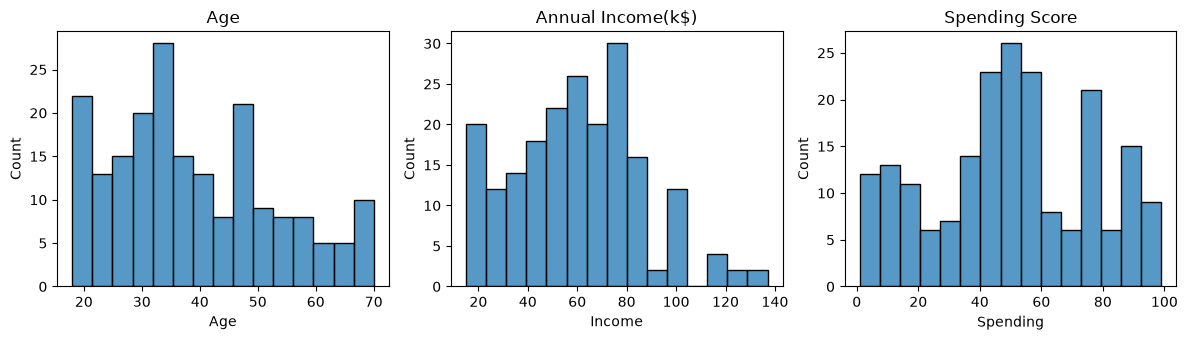

In [ ]:
plt.figure(figsize=(12,3.5))

plt.subplot(1,3,1)
sns.histplot(df["Age"],bins=15)
plt.title("Age")

plt.subplot(1,3,2)
sns.histplot(df["Income"],bins=15)
plt.title("Annual Income(k$)")

plt.subplot(1,3,3)
sns.histplot(df["Spending"],bins=15)
plt.title("Spending Score")

plt.tight_layout()
plt.show()


Age: most customers are in their 20s, 30s and 40s, with fewer above 60. Income: centred on about 60 thousand dollars, with only a few customers above 100. Spending score: spread across the whole range from 1 to 99, with no single peak. Nothing looks like an error, and the highest incomes (up to 137) are real customers, so none are removed.

### 5.2 Relationships between columns
The correlation heatmap shows straight-line relationships between the columns. The scatter plot of income against spending shows whether customers form natural groups.

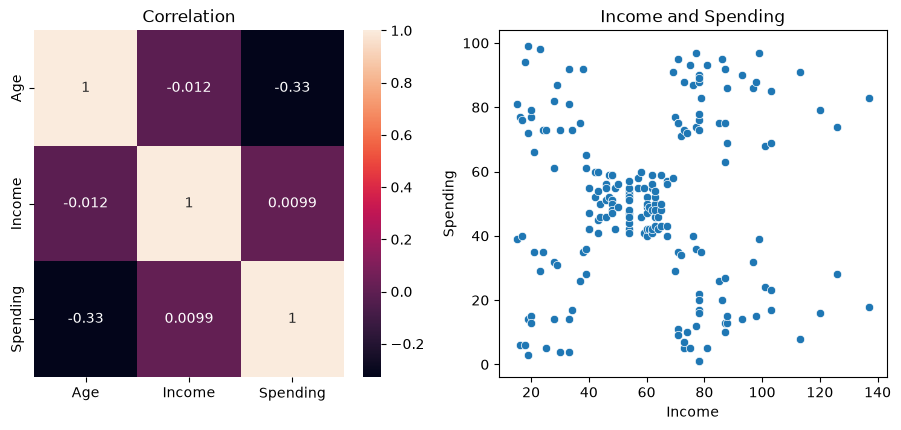

In [41]:
plt.figure(figsize=(11, 4.5))
plt.subplot(1,2,1)
sns.heatmap(df[["Age","Income","Spending"]].corr(),annot=True)
plt.title("Correlation")

plt.subplot(1,2,2)
sns.scatterplot(x="Income",y="Spending",data=df)
plt.title("Income and Spending")

plt.tight_layout
plt.show()

Income and spending have almost no straight-line relationship (0.01), and age and spending are weakly negative (-0.33: younger customers tend to score higher). So a single line cannot describe the customers. But the scatter plot shows clear clumps: a block in the middle and four groups around the corners. That is exactly the pattern clustering can find.

---
## 6. Feature Scaling
The clustering uses two features that describe purchasing behaviour: **Income** (what the customer can afford) and **Spending** (how much they spend). Age and Gender are left out so that the segments are based on spending behaviour.

K-Means groups customers by the **distance** between them, so a column with larger numbers would count for more. `StandardScaler` rescales each column to mean 0 and standard deviation 1, so both count equally. No train/test split is needed, because there is no target to predict.

In [42]:
from sklearn.preprocessing import StandardScaler

In [43]:
x = df[["Income","Spending"]]

sc = StandardScaler()
x_scaled = sc.fit_transform(x)

In [45]:
#Checking the scaled column has mean 0 and std 1
print(x_scaled.mean(axis=0).round(2))
print(x_scaled.std(axis=0).round(2))

[-0. -0.]
[1. 1.]


Both scaled columns have a mean of 0 and a standard deviation of 1 (`-0.` is simply a tiny negative zero).

---
## 7. Choosing the Number of Clusters (K)
K-Means needs the number of clusters to be chosen in advance. Two methods are used and compared.

### 7.1 Elbow method
Inertia measures how spread out the customers are within their clusters. It always falls as K grows, so look for the "elbow", the point after which adding clusters helps very little.

In [46]:
from sklearn.cluster import KMeans

In [50]:
inertia = []
for k in range(1,11):
    km = KMeans(n_clusters=k,n_init=10,random_state=42)
    km.fit(x_scaled)
    inertia.append(km.inertia_)
print([round(i, 1) for i in inertia])

[400.0, 269.7, 157.7, 108.9, 65.6, 55.1, 44.9, 37.2, 32.4, 30.0]


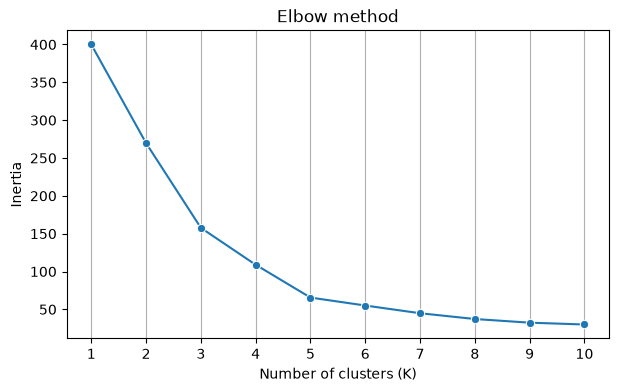

In [52]:

plt.figure(figsize=(7, 4))
sns.lineplot(x=range(1, 11), y=inertia, marker="o")
plt.xticks(range(1, 11))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.grid(axis = "x")
plt.show()

The curve drops steeply until K = 5 and then flattens (65.6 at K = 5, then 55.1, 44.9 and so on). The bend is at 5, so five clusters is the first candidate. The elbow can be hard to judge by eye, which is why you check it with the silhouette score in the next step.

### 7.2 Silhouette score
The silhouette score measures how well each customer fits its own cluster compared with the nearest other cluster. It runs from -1 to 1, and **higher is better**. It needs at least 2 clusters, so K starts from 2.

In [53]:
from sklearn.metrics import silhouette_score

In [57]:
ss = []

for k in range(2,11):
    km1 = KMeans(n_clusters=k,n_init=10,random_state=42)
    labels = km1.fit_predict(x_scaled)
    ss.append(silhouette_score(x_scaled,labels))

In [59]:
for k, s in zip(range(2,11),ss):
    print(k,round(s,4))

2 0.3213
3 0.4666
4 0.4939
5 0.5547
6 0.5399
7 0.5281
8 0.4552
9 0.4571
10 0.4432


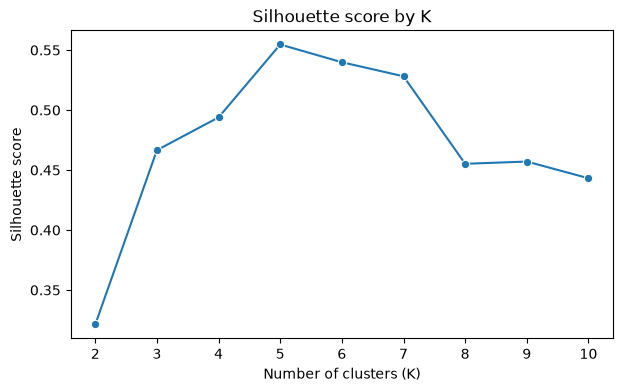

In [60]:
plt.figure(figsize=(7,4))
sns.lineplot(x=range(2,11),y = ss, marker="o")
plt.xticks(range(2,11))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score by K")
plt.show()


The score is highest at K = 5 (0.5547) and lower for every other K (0.5399 at 6, 0.4939 at 4). The elbow and the silhouette score agree, so K = 5 is the number of clusters to use. A score above 0.5 means the clusters are reasonably well separated.

---
## 8. Fitting K-Means with K = 5
Both the elbow method and the silhouette score point to **K = 5**. The model is fitted with `random_state=42` so the result is repeatable, and `n_init=10` so it is run from 10 starting points and the best result is kept. Each customer is given a cluster number, which is stored in a new `Cluster` column.

> The cluster numbers (0 to 4) are only labels. The same groups could get different numbers on another run or computer.

In [62]:
kmeans = KMeans(n_clusters=5,n_init=10,random_state=42)
df["Cluster"] = kmeans.fit_predict(x_scaled)


In [65]:
print(round(silhouette_score(x_scaled,df["Cluster"]),4))
print(df["Cluster"].value_counts().sort_index())
df.head()

0.5547
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


,Gender,Age,Income,Spending,Cluster
0,Male,19,15,39,4
1,Male,21,15,81,2
2,Female,20,16,6,4
3,Female,23,16,77,2
4,Female,31,17,40,4


Each customer now has a cluster number from 0 to 4. The groups have 81, 39, 22, 35 and 23 customers. 

## 9. Visualizing the Clusters
Each cluster is shown in a different colour. The black X marks are the cluster centres (centroids), converted back to the original units with `inverse_transform`.

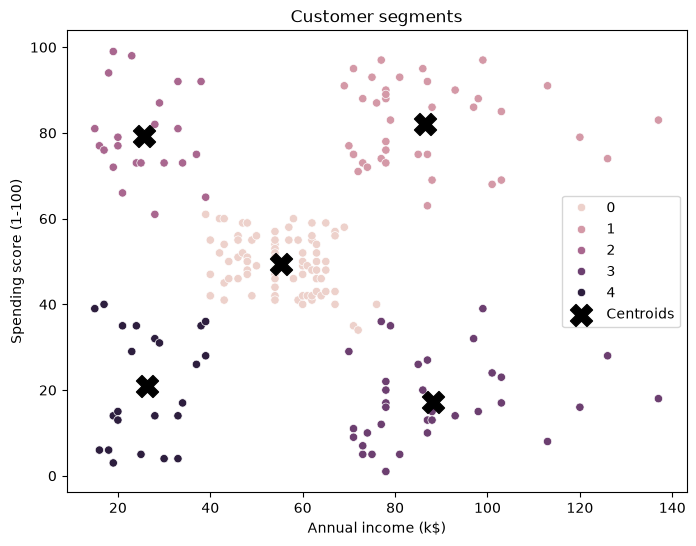

In [73]:
centers = sc.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x="Income", y="Spending", hue="Cluster")
plt.scatter(centers[:,0],centers[:,1],c="black",s=250,marker="X",label="Centroids")
plt.xlabel("Annual income (k$)")
plt.ylabel("Spending score (1-100)")
plt.title("Customer segments")
plt.legend()
plt.show()



The five groups are clearly separated: one in the middle and one in each corner of the chart.

---
## 10. Profiling the Segments
To describe each segment, calculate for every cluster the average age, income and spending score, the number of customers and the percentage of women.

In [78]:
profile = df.groupby("Cluster")[["Age","Income","Spending"]].mean()
profile["Customers"]= df["Cluster"].value_counts().sort_index()
profile["Female %"] = (df["Gender"].eq("Female").groupby(df["Cluster"]).mean() * 100).round(0)
print(profile)

               Age     Income   Spending  Customers  Female %
Cluster                                                      
0        42.716049  55.296296  49.518519         81      59.0
1        32.692308  86.538462  82.128205         39      54.0
2        25.272727  25.727273  79.363636         22      59.0
3        41.114286  88.200000  17.114286         35      46.0
4        45.217391  26.304348  20.913043         23      61.0


Cluster 0 (81 customers) has middle income and middle spending. Cluster 1 (39) has high income and high spending. Cluster 2 (22) is the youngest group (average age 25) with low income but high spending. Cluster 3 (35) has high income but low spending. Cluster 4 (23) has low income and low spending. Age differs a lot between groups, but the share of women is similar (about 46% to 61%), so gender does not drive these segments.

---
## 11. Segment Names and Recommendations
Each segment is given a name, with one suggested action.

| Segment | Cluster | Customers | Profile | Suggested action |
|---|---|---|---|---|
| **Premium customers** | 1 | 39 | High income, high spending | Keep them loyal with VIP offers and early access to new products |
| **Careful big earners** | 3 | 35 | High income, low spending | They can afford more but are not buying; test targeted promotions on premium items |
| **Young enthusiasts** | 2 | 22 | Low income, high spending, average age 25 | Offer trendy products, student deals and loyalty rewards |
| **Average customers** | 0 | 81 | Middle income, middle spending | The largest group; keep them with regular discounts and seasonal campaigns |
| **Budget savers** | 4 | 23 | Low income, low spending | Low priority for costly campaigns; reach them with low-cost clearance offers |

---
## 12. Conclusion

I used K-Means clustering to segment 200 mall customers by annual income and spending score. The features were scaled with StandardScaler, and the number of clusters was chosen with the elbow method and the silhouette score, which was highest (0.55) at K = 5. The five segments are: premium customers (high income, high spending), careful high earners (high income, low spending), young enthusiasts (low income, high spending), average customers (middle income and spending) and budget savers (low income, low spending). Each can be treated differently, for example VIP offers for the first group and targeted promotions for the second. Limitations are the small dataset, the use of only two features, and that the spending score is supplied by the mall rather than measured from real purchases. Future work could add age and gender, or try other methods such as hierarchical clustering.